The objective is to accurately predict medical insurance costs based on patient data. In this project,we build various regression models and compare their performance to recommend the best one to the stakeholders.

In [291]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error,mean_absolute_error,r2_score
from sklearn.linear_model import LinearRegression
from sklearn import metrics
from sklearn import preprocessing
from scipy import stats
from statsmodels.stats.outliers_influence import variance_inflation_factor

**DATA DICTIONARY**

> age	        : Age of the primary beneficiary

> sex	        : Gender of the insurance policyholder (female/male)

> bmi	        : Body Mass Index (kg/m²)

> children	: Number of dependents covered under the insurance

> smoker	    : Smoking status (yes/no)

> region	    : Residential area in the US (northeast, southeast, southwest, northwest)

> charges	    : Individual medical costs billed by health insurance


***1. Import and Load the Data***

In [292]:
df= pd.read_csv("C:/Users/LochanRai_lsntoq1/B-15 DS/MiniProject6/Medical Insurance cost Prediction.csv")
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [293]:
df.tail()

,age,sex,bmi,children,smoker,region,charges
1333,50,male,30.97,3,no,northwest,10600.5483
1334,18,female,31.92,0,no,northeast,2205.9808
1335,18,female,36.85,0,no,southeast,1629.8335
1336,21,female,25.80,0,no,southwest,2007.9450
1337,61,female,29.07,0,yes,northwest,29141.3603


In [294]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 94.5 KB


Age, bmi and charges are numeric columns whereas sex smoker and region are string columns. Total we have 1338 rows and 7 columns.

In [295]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,1338.0,39.207025,14.049960,18.0000,27.00000,39.000,51.000000,64.00000
bmi,1338.0,30.663397,6.098187,15.9600,26.29625,30.400,34.693750,53.13000
children,1338.0,1.094918,1.205493,0.0000,0.00000,1.000,2.000000,5.00000
charges,1338.0,13270.422265,12110.011237,1121.8739,4740.28715,9382.033,16639.912515,63770.42801


> The age group taken in the dataset is 18 to 64 yrs with average age 30 years.

> Average medical cost is $13270.

In [296]:
df.describe(include= "object")

C:\Users\LochanRai_lsntoq1\AppData\Local\Temp\ipykernel_2156\3501404678.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include= "object")


,sex,smoker,region
count,1338,1338,1338
unique,2,2,4
top,male,no,southeast
freq,676,1064,364


***2. Exploratory Data Analysis (EDA)***

In [297]:
df.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [298]:
df.duplicated().sum()

np.int64(1)

In [299]:
df[df.duplicated()]

,age,sex,bmi,children,smoker,region,charges
581,19,male,30.59,0,no,northwest,1639.5631


In [300]:
df.drop_duplicates()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,male,30.970,3,no,northwest,10600.54830
1334,18,female,31.920,0,no,northeast,2205.98080
1335,18,female,36.850,0,no,southeast,1629.83350
1336,21,female,25.800,0,no,southwest,2007.94500


In [301]:
df_numerical = df.select_dtypes(include=np.number)
df_numerical

,age,bmi,children,charges
0,19,27.900,0,16884.92400
1,18,33.770,1,1725.55230
2,28,33.000,3,4449.46200
3,33,22.705,0,21984.47061
4,32,28.880,0,3866.85520
...,...,...,...,...
1333,50,30.970,3,10600.54830
1334,18,31.920,0,2205.98080
1335,18,36.850,0,1629.83350
1336,21,25.800,0,2007.94500


In [302]:
df_categorical = df.select_dtypes(exclude=np.number)
df_categorical

,sex,smoker,region
0,female,yes,southwest
1,male,no,southeast
2,male,no,southeast
3,male,no,northwest
4,male,no,northwest
...,...,...,...
1333,male,no,northwest
1334,female,no,northeast
1335,female,no,southeast
1336,female,no,southwest


In [303]:
df.nunique().value_counts()

2       2
47      1
548     1
6       1
4       1
1337    1
Name: count, dtype: int64

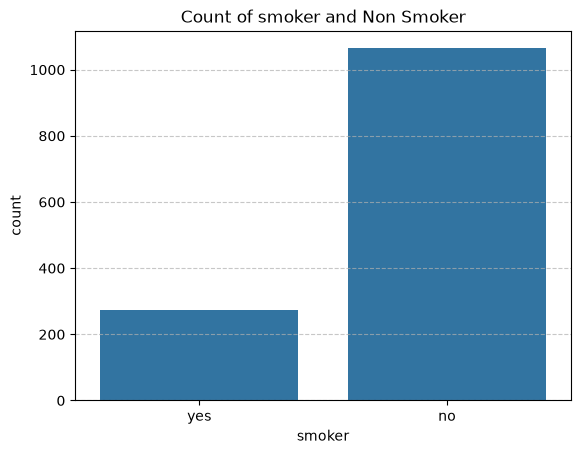

In [304]:
sns.countplot(data=df, x='smoker')
plt.title('Count of smoker and Non Smoker')
plt.grid(True,linestyle='--', alpha=0.7, axis='y')
plt.show()

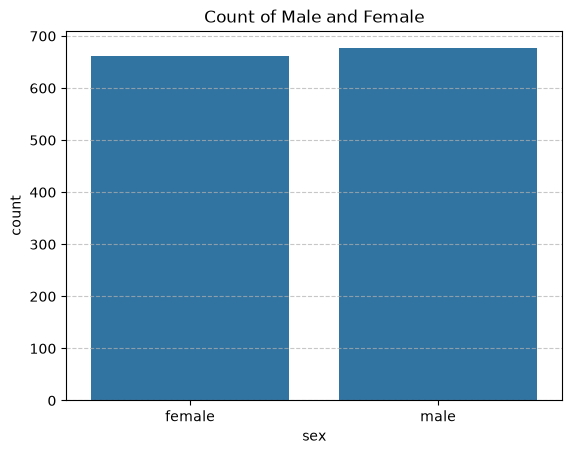

In [305]:
sns.countplot(data=df, x='sex')
plt.title('Count of Male and Female')
plt.grid(True,linestyle='--', alpha=0.7, axis='y')
plt.show()

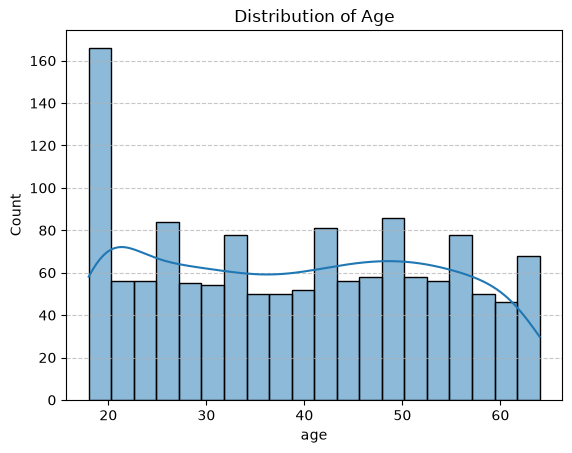

In [306]:
sns.histplot(data=df, x='age', bins=20, kde=True)
plt.title('Distribution of Age')
plt.grid(True,linestyle='--', alpha=0.7, axis='y')
plt.show()

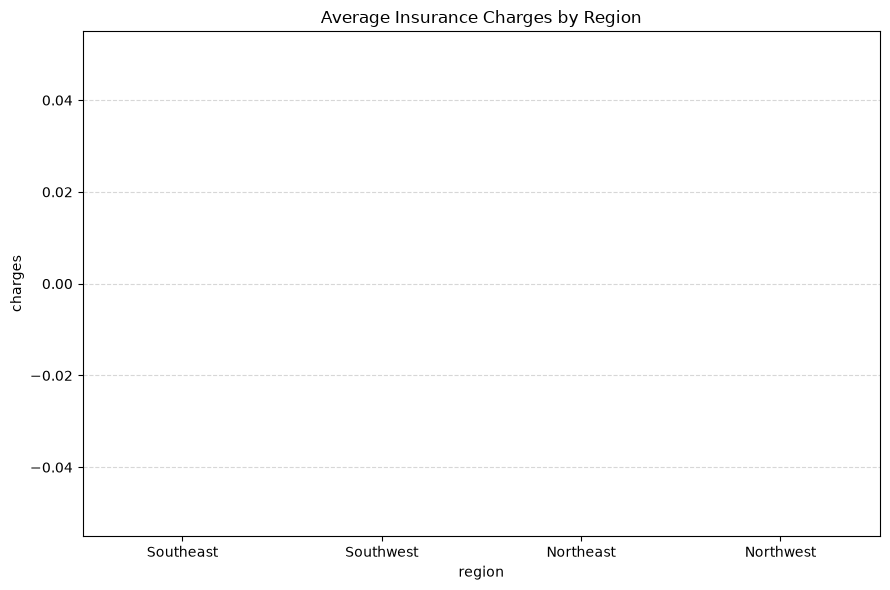

In [307]:
plt.figure(figsize=(9, 6))
ax = sns.barplot(data=df, x='region', y='charges', order=[0, 1, 2, 3])
ax.set_xticks([0, 1, 2, 3])
ax.set_xticklabels(['Southeast', 'Southwest', 'Northeast', 'Northwest'])
plt.title('Average Insurance Charges by Region')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

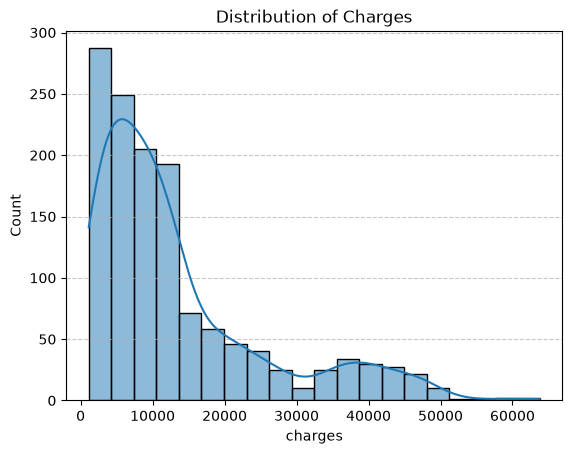

In [308]:
sns.histplot(data=df, x='charges', bins=20, kde=True)
plt.title('Distribution of Charges')
plt.grid(True,linestyle='--', alpha=0.7, axis='y')
plt.show()

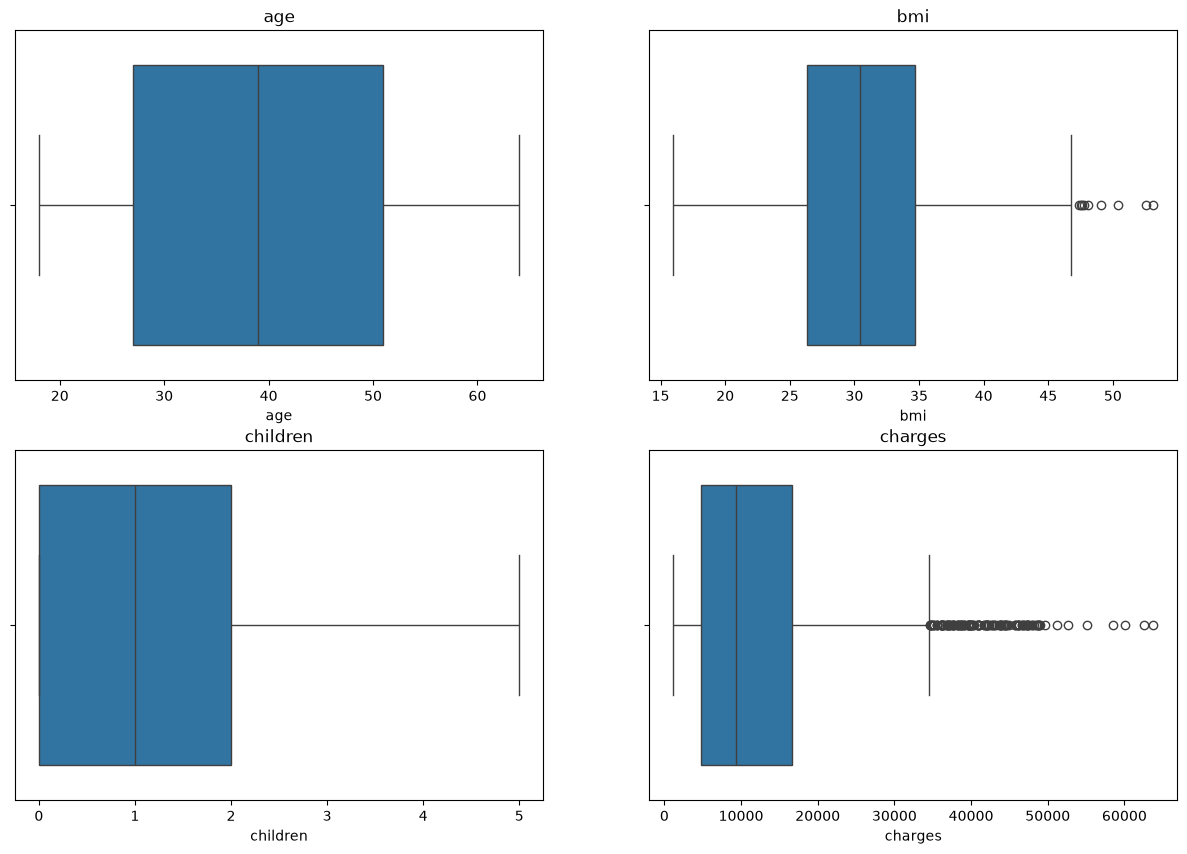

In [309]:
cols = ['age', 'bmi', 'children', 'charges']
figure, axes = plt.subplots(2, 2, figsize=(15, 10))
for i, ax in enumerate(axes.flatten()):
    sns.boxplot(data=df, x=cols[i], ax=ax)
    ax.set_title(cols[i])

In [310]:
df_numerical.corr()

,age,bmi,children,charges
age,1.000000,0.109272,0.042469,0.299008
bmi,0.109272,1.000000,0.012759,0.198341
children,0.042469,0.012759,1.000000,0.067998
charges,0.299008,0.198341,0.067998,1.000000


> There is positive correaltion between age and insurance charges. As the age will increase the insurances will become costlier.

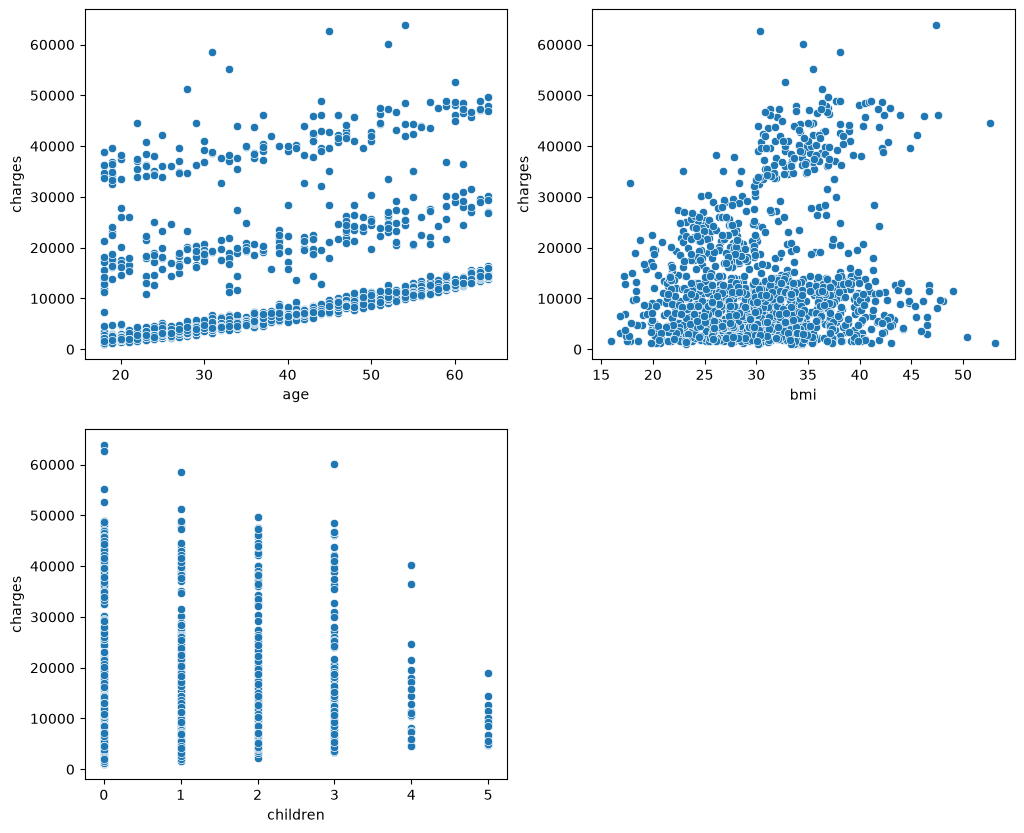

In [311]:
target = 'charges'
features = [col for col in df_numerical.columns if col != target]

plt.figure(figsize=(12,10))
for col in features:
  plt.subplot(2, 2, df_numerical.columns.get_loc(col) + 1)
  sns.scatterplot(data =df_numerical, x= col,y = 'charges')
plt.show()

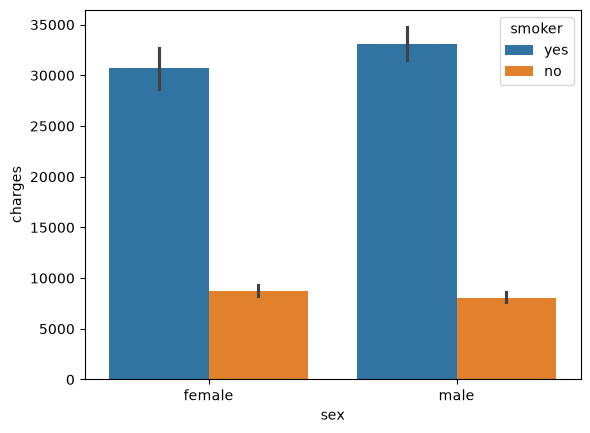

In [312]:
sns.barplot(x="sex",y="charges",hue="smoker",data=df)
plt.xlabel='sex'
plt.ylabel='charges'
plt.show()

In [313]:
# charges per region

df_region_sort = df.groupby('region',as_index=False)['charges'].sum().sort_values(by='charges', ascending=False)
df_region_sort

,region,charges
2,southeast,5.363690e+06
0,northeast,4.343669e+06
1,northwest,4.035712e+06
3,southwest,4.012755e+06


***3. Missing Values & Outlier Treatment***

<Axes: ylabel='charges'>

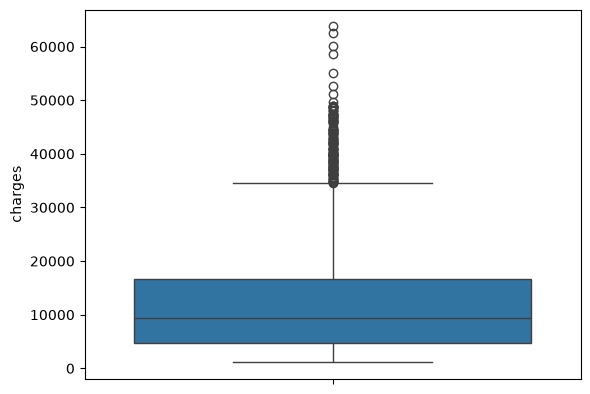

In [314]:
sns.boxplot(data=df, y='charges')

<Axes: ylabel='bmi'>

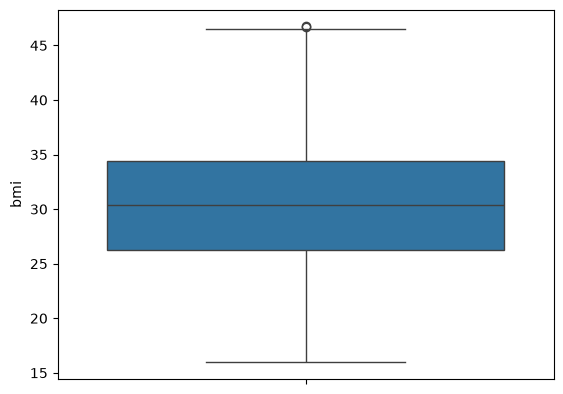

In [315]:
# to treat outlier in bmi, we are choosing mean

Q1 = df['bmi'].quantile(0.25)
Q3 = df['bmi'].quantile(0.75)

IQR = Q3 - Q1

Upper_bound = Q3 + 1.5 * IQR
lower_bound = Q1 - 1.5 * IQR

df['bmi'] = np.where(df['bmi'] > Upper_bound, df['bmi'].mean(), df['bmi'])

sns.boxplot(data=df, y='bmi')

In [316]:
# checking distribution of age
df['age'].value_counts(ascending=False)

age
18    69
19    68
46    29
52    29
48    29
20    29
45    29
47    29
51    29
50    29
28    28
25    28
23    28
27    28
22    28
26    28
24    28
21    28
53    28
54    28
49    28
31    27
30    27
41    27
40    27
43    27
44    27
29    27
42    27
33    26
32    26
56    26
34    26
55    26
57    26
37    25
59    25
35    25
38    25
36    25
58    25
39    25
60    23
62    23
63    23
61    23
64    22
Name: count, dtype: int64

In [317]:
# label encoding
df['sex'] = df['sex'].map({'male': 0, 'female': 1})
df['smoker'] = df['smoker'].map({'no': 0, 'yes': 1})
df['region'] = df['region'].map({'southeast': 0, 'southwest': 1, 'northeast': 2, 'northwest': 3})

In [318]:
df.drop('children',axis=1,inplace=True)

C:\Users\LochanRai_lsntoq1\AppData\Local\Temp\ipykernel_2156\1961289479.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop('children',axis=1,inplace=True)


***4. Feature Engineering & Preprocessing***

In [319]:
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import Ridge
from sklearn.linear_model import Lasso
from sklearn.linear_model import ElasticNet
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.ensemble import AdaBoostRegressor
from sklearn.ensemble import VotingRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import BaggingRegressor
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
from lightgbm import LGBMRegressor

from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import r2_score
from sklearn.metrics import mean_squared_error

from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import LabelEncoder 
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import PowerTransformer

In [320]:
#df.drop('children',axis=1)

In [321]:
x = df.drop(['charges'],axis=1)
y = df['charges']

In [322]:
x

,age,sex,bmi,smoker,region
0,19,1,27.900,1,1
1,18,0,33.770,0,0
2,28,0,33.000,0,0
3,33,0,22.705,0,3
4,32,0,28.880,0,3
...,...,...,...,...,...
1333,50,0,30.970,0,3
1334,18,1,31.920,0,2
1335,18,1,36.850,0,0
1336,21,1,25.800,0,1


In [323]:
x_train, x_test, y_train, y_test = train_test_split(x,y,test_size=0.2,random_state=3)
print("x_train length:",x_train.shape)
print("y_train length :",y_train.shape)

x_train length: (1070, 5)
y_train length : (1070,)


In [324]:
# Standardize features and target using training data only
x_standard_scaler = StandardScaler()
y_standard_scaler = StandardScaler()

x_train_standardized = x_standard_scaler.fit_transform(x_train)
x_test_standardized = x_standard_scaler.transform(x_test)

y_train_standardized = y_standard_scaler.fit_transform(
    y_train.to_numpy().reshape(-1, 1)
).ravel()
y_test_standardized = y_standard_scaler.transform(
    y_test.to_numpy().reshape(-1, 1)
).ravel()

In [325]:
print("x_test length :",x_test.shape)
print("y_test length :",y_test.shape)

x_test length : (268, 5)
y_test length : (268,)


***5. Model Building: Try Multiple Regressors***

##### a. Store performance metrices in the list

In [326]:
training_scores_r2 = []
training_scores_adj_r2 = []
training_scores_rmse = []

testing_scores_r2 = []
testing_scores_adj_r2 = []
testing_scores_rmse = []

##### b. Create a function for evaluate model

In [327]:
def evaluate_model_performance(model, x_train, y_train, x_test, y_test):
    """
    Evaluates R², Adjusted R², and RMSE of a given model on training and testing data.
    
    Parameters:
    - model: The machine learning model to evaluate
    - x_train: Training feature set
    - y_train: Training target values
    - x_test: Testing feature set
    - y_test: Testing target values
    - training_scores: List to store training R² scores
    - testing_scores: List to store testing R² scores
    """
    # Fit the model
    model.fit(x_train, y_train)
    
    # Predictions for training and testing data
    y_train_pred = model.predict(x_train)
    y_test_pred = model.predict(x_test)
    
    # Calculate R² scores
    train_r2 = r2_score(y_train, y_train_pred) * 100
    test_r2 = r2_score(y_test, y_test_pred) * 100
    
    # Calculate Adjusted R² scores
    n_train, p_train = x_train.shape
    n_test, p_test = x_test.shape
    train_adj_r2 = 100 * (1 - (1 - train_r2 / 100) * (n_train - 1) / (n_train - p_train - 1))
    test_adj_r2 = 100 * (1 - (1 - test_r2 / 100) * (n_test - 1) / (n_test - p_test - 1))
    
    # Calculate RMSE scores
    train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred))
    test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))
    
    # Append scores to respective lists
    training_scores_r2.append(train_r2)
    training_scores_adj_r2.append(train_adj_r2)
    training_scores_rmse.append(train_rmse)
    testing_scores_r2.append(test_r2)
    testing_scores_adj_r2.append(test_adj_r2) 
    testing_scores_rmse.append(test_rmse) 
    
    # Display scores
    print(f"{model.__class__.__name__} Performance Metrics:")
    print(f"Training Data: R² = {train_r2:.2f}%, Adjusted R² = {train_adj_r2:.2f}%, RMSE = {train_rmse:.4f}")
    print(f"Testing Data : R² = {test_r2:.2f}%, Adjusted R² = {test_adj_r2:.2f}%, RMSE = {test_rmse:.4f}\n")

**1. Linear Regression** 

In [328]:
evaluate_model_performance(
    model=LinearRegression(),
    x_train=x_train_standardized,
    y_train=y_train_standardized,
    x_test=x_test_standardized,
    y_test=y_test_standardized
)

LinearRegression Performance Metrics:
Training Data: R² = 74.72%, Adjusted R² = 74.60%, RMSE = 0.5028
Testing Data : R² = 74.52%, Adjusted R² = 74.03%, RMSE = 0.5140



**ANALYSIS**

**A. R² score: 93.65% and 93.86%**

R² tells you how much of the variation in your target variable is explained by your model.
- Training R² = 93.65%: Your model explains approximately 93.65% of the variation in the target values in the training dataset.
- Testing R² = 93.86%: Your model explains approximately 93.86% of the variation in the unseen test dataset.
The testing result is particularly encouraging because the model performs well on data it wasn't trained on.

An R² of 93.86% does not mean 93.86% of your predictions are exactly correct. It measures explained variation, not the percentage of correct predictions.

**B. Adjusted R²: 93.61% and 93.72%**

Adjusted R² is similar to R², but it also accounts for the number of predictors relative to the number of observations.

It penalizes adding predictors that do not contribute enough explanatory power.

Your results show that Adjusted R² is only slightly lower than R², which is encouraging. However, this alone does not prove that every feature is useful.

**C. RMSE: 0.0480 and 0.0484**

RMSE measures prediction errors, penalizing larger errors more heavily.
- Training RMSE = 0.0480
- Testing RMSE = 0.0484
The test error is only slightly higher than the training error. This is generally a good sign.

Important: RMSE is measured in the same units as the target variable. If you scaled your target variable before training, an RMSE of 0.0484 may be in scaled units rather than the original units. If you scaled only the input features (X), the RMSE remains in the target variable's units.

In [329]:
evaluate_model_performance(
    model=Ridge(alpha=1.0),
    x_train=x_train_standardized,
    y_train=y_train_standardized,
    x_test=x_test_standardized,
    y_test=y_test_standardized
)

Ridge Performance Metrics:
Training Data: R² = 74.72%, Adjusted R² = 74.60%, RMSE = 0.5028
Testing Data : R² = 74.52%, Adjusted R² = 74.04%, RMSE = 0.5140



**2. Decision Tree Regressor**

In [330]:
evaluate_model_performance(
    model=DecisionTreeRegressor(),
    x_train=x_train_standardized,
    y_train=y_train_standardized,
    x_test=x_test_standardized,
    y_test=y_test_standardized
)

DecisionTreeRegressor Performance Metrics:
Training Data: R² = 99.75%, Adjusted R² = 99.74%, RMSE = 0.0505
Testing Data : R² = 75.27%, Adjusted R² = 74.79%, RMSE = 0.5064



**3. Random Forest Regressor**

In [331]:
evaluate_model_performance(
    model=RandomForestRegressor(),
    x_train=x_train_standardized,
    y_train=y_train_standardized,
    x_test=x_test_standardized,
    y_test=y_test_standardized
)

RandomForestRegressor Performance Metrics:
Training Data: R² = 97.32%, Adjusted R² = 97.31%, RMSE = 0.1636
Testing Data : R² = 83.77%, Adjusted R² = 83.46%, RMSE = 0.4102



**4. Ada Boost Regressor**

In [332]:
evaluate_model_performance(
    model=RandomForestRegressor(),
    x_train=x_train_standardized,
    y_train=y_train_standardized,
    x_test=x_test_standardized,
    y_test=y_test_standardized
)

RandomForestRegressor Performance Metrics:
Training Data: R² = 97.46%, Adjusted R² = 97.45%, RMSE = 0.1593
Testing Data : R² = 83.65%, Adjusted R² = 83.34%, RMSE = 0.4117



**5. Gradient Boosting**

In [333]:
evaluate_model_performance(
    model=GradientBoostingRegressor(),
    x_train=x_train_standardized,
    y_train=y_train_standardized,
    x_test=x_test_standardized,
    y_test=y_test_standardized
)

GradientBoostingRegressor Performance Metrics:
Training Data: R² = 89.79%, Adjusted R² = 89.75%, RMSE = 0.3195
Testing Data : R² = 85.52%, Adjusted R² = 85.25%, RMSE = 0.3874



**6. XGB Regressor**

In [334]:
evaluate_model_performance(
    model=XGBRegressor(),
    x_train=x_train_standardized,
    y_train=y_train_standardized,
    x_test=x_test_standardized,
    y_test=y_test_standardized
)

XGBRegressor Performance Metrics:
Training Data: R² = 99.24%, Adjusted R² = 99.24%, RMSE = 0.0870
Testing Data : R² = 80.46%, Adjusted R² = 80.09%, RMSE = 0.4501



***6. Model Evaluation & Overfitting Check***

In [335]:
# preprunning Decision Tree to reduce overfitting

evaluate_model_performance(
    model=DecisionTreeRegressor(max_depth=10,
    min_samples_split=10,
    min_samples_leaf=5,
    random_state=42),
    x_train=x_train,
    y_train=y_train,
    x_test=x_test,
    y_test=y_test
) 

DecisionTreeRegressor Performance Metrics:
Training Data: R² = 90.55%, Adjusted R² = 90.51%, RMSE = 3707.2944
Testing Data : R² = 84.40%, Adjusted R² = 84.10%, RMSE = 4850.5885



In [336]:
candidates = {
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(random_state=42),
    "AdaBoost": AdaBoostRegressor(random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
    "XGBoost": XGBRegressor(random_state=42),
}

results = []

for name, candidate in candidates.items():
    candidate.fit(x_train_standardized, y_train_standardized)
    train_pred = candidate.predict(x_train_standardized)
    test_pred = candidate.predict(x_test_standardized)

    results.append({
        "Model": name,
        "Train R²": r2_score(y_train_standardized, train_pred),
        "Test R²": r2_score(y_test_standardized, test_pred),
        "Test RMSE": np.sqrt(mean_squared_error(y_test_standardized, test_pred)),
    })

results_df = pd.DataFrame(results).sort_values(
    by="Test R²", ascending=False
)
results_df

,Model,Train R²,Test R²,Test RMSE
5,Gradient Boosting,0.897946,0.855266,0.387397
3,Random Forest,0.973610,0.835000,0.413630
4,AdaBoost,0.841630,0.832123,0.417221
6,XGBoost,0.992437,0.804589,0.450137
2,Decision Tree,0.997454,0.753304,0.505769
1,Ridge,0.747182,0.745237,0.513971
0,Linear Regression,0.747183,0.745208,0.514001


In [337]:
import joblib

selected_name = results_df.iloc[0]["Model"]
assert selected_name == "Gradient Boosting", f"Top model is {selected_name}, not Random Forest"

model = candidates[selected_name]
joblib.dump(model, "medical_insurance.pkl")

['medical_insurance.pkl']

In [338]:
joblib.dump(x_standard_scaler, "x_scaler.pkl")
joblib.dump(y_standard_scaler, "y_scaler.pkl")

['y_scaler.pkl']

***7. Hyperparameter Tuning***

In [339]:
vif_columns = [col for col in df.columns if col != 'charges']
vif1 = df.drop('charges', axis=1).copy()


In [340]:
variable = vif1
vif = pd.DataFrame()
vif['Variance Inflation Factor'] = [variance_inflation_factor(variable, i) for i in range(variable.shape[1])]
vif['Features'] = vif_columns

In [341]:
vif.sort_values(by="Variance Inflation Factor", ascending=False)

,Variance Inflation Factor,Features
2,1.083582,bmi
4,1.070766,region
0,1.015583,age
3,1.009495,smoker
1,1.008038,sex


> VIF of all the cols are less than 10 which shows that there is no multicollinearity

***8. Model Comparison Table***

In [342]:
models = [
    "Linear Regression",
    "Ridge",
    "Decision Tree",
    "Random Forest",
    "Ada Boost",
    "XGBoost",
    "Pruned Decision Tree"
   ]

In [343]:
df_model = pd.DataFrame({
        "Algorithms": models,
        "Training Score R2": training_scores_r2,
        "Training Score Adjusted R2": training_scores_adj_r2,
        "Training Score RMSE": training_scores_rmse,
        "Testing Score R2": testing_scores_r2,
        "Testing Score Adjusted R2": testing_scores_adj_r2,
        "Testing Score RMSE": testing_scores_rmse,
})

df_model_sort = df_model.sort_values(
        by="Testing Score R2", ascending=False
)
df_model_sort
				   
df_model_sort = df_model.sort_values(by="Testing Score R2", ascending=False)
df_model_sort

ValueError: All arrays must be of the same length

In [ ]:
# Plotting bar chart for training and testing scores
ax = model.plot(
    x="Algorithms",
    y=["Training Score R2","Testing Score R2"],
    kind="bar",
    figsize=(15, 9),
    colormap="Set3",
    width=0.8
)

# Adding title and labels
plt.title("Performance Visualization of Different Models", fontsize=18, fontweight="bold", pad=20)
plt.xlabel("Algorithms", fontsize=12)
plt.ylabel("Scores", fontsize=12)
plt.xticks(rotation=90, ha='right', fontsize=16)

# Adding data labels to each bar
for container in ax.containers:
    ax.bar_label(container, fmt='%.2f', label_type='edge', fontsize=9, padding=3)

plt.tight_layout()
plt.show()

NameError: name 'model' is not defined